# 03 - Análisis de variables y reducción de dimensión

**Proyecto de aula - Modelos y Simulación de Sistemas II**

**Integrantes:** Kelly Julieth Arango Henao, Lisbeth Cataño Sepulveda

## Introducción

En este notebook se realiza el análisis individual de las variables y se aplican técnicas de reducción de dimensión al conjunto de datos utilizado para la detección de fraude con tarjetas de crédito.

Inicialmente, se estudia la relación de cada variable con la clase objetivo, con el propósito de identificar cuáles características aportan mayor información para diferenciar las transacciones legítimas de las fraudulentas.

Posteriormente, se aplican dos técnicas de reducción de dimensión: Análisis de Componentes Principales (PCA), como método lineal, y UMAP, como método no lineal.

Finalmente, se evalúa el desempeño de los dos mejores modelos obtenidos en el notebook 02, utilizando las características reducidas. Los resultados se comparan con los obtenidos utilizando el conjunto original de variables.

## Objetivos

- Analizar la capacidad discriminativa de las variables.
- Identificar características que podrían eliminarse.
- Aplicar PCA para reducir el número de variables.
- Aplicar UMAP para obtener una representación de menor dimensión.
- Comparar el desempeño de los modelos antes y después de la reducción.

In [1]:
!pip install umap-learn -q

In [2]:
import os
import time
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import pointbiserialr

from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    GridSearchCV
)

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.decomposition import PCA

from sklearn.feature_selection import mutual_info_classif

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

from umap import UMAP

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")

SEMILLA = 42

np.random.seed(SEMILLA)

CARPETA_RESULTADOS = (
    "../resultados"
    if os.path.isdir("..") and os.path.isdir("../notebooks")
    else "resultados"
)

os.makedirs(CARPETA_RESULTADOS, exist_ok=True)

print("Librerías cargadas correctamente.")
print("Carpeta de resultados:", CARPETA_RESULTADOS)

Librerías cargadas correctamente.
Carpeta de resultados: resultados


## 1. Carga y preparación de los datos

Se carga el conjunto de datos Credit Card Fraud Detection y se eliminan los registros duplicados, siguiendo el mismo procedimiento utilizado en los notebooks anteriores.

Posteriormente, se separan las variables de entrada y la variable objetivo. Se conserva la semilla utilizada en el notebook 02 para mantener la misma división de entrenamiento y prueba.

In [3]:
# Buscar el archivo de datos

candidatos = [
    "../data/creditcard.csv",
    "data/creditcard.csv",
    "/content/drive/MyDrive/creditcard.csv",
    "/content/drive/MyDrive/data/creditcard.csv",
    "/content/drive/MyDrive/Colab Notebooks/data/creditcard.csv",
    "creditcard.csv"
]

RUTA_DATOS = None

for ruta in candidatos:
    if os.path.exists(ruta):
        RUTA_DATOS = ruta
        break

# Si no se encontro y estamos en Google Colab, intentar conectar Google Drive
# antes de pedir que se suba el archivo manualmente (igual que en los
# notebooks 01 y 02).
if RUTA_DATOS is None:
    try:
        import google.colab
        en_colab = True
    except ImportError:
        en_colab = False

    if en_colab:
        from google.colab import drive
        print("No se encontro el archivo. Intentando conectar Google Drive...")
        drive.mount('/content/drive')

        for ruta in candidatos:
            if os.path.exists(ruta):
                RUTA_DATOS = ruta
                break

        if RUTA_DATOS is None:
            print("No se encontro en Drive. Sube el archivo creditcard.csv manualmente:")
            from google.colab import files
            archivos = files.upload()

            if archivos:
                RUTA_DATOS = list(archivos.keys())[0]

if RUTA_DATOS is None:
    raise FileNotFoundError(
        "No se encontro creditcard.csv. "
        "Verifica su ubicacion o cargalo manualmente."
    )

df = pd.read_csv(RUTA_DATOS)

filas_originales = len(df)

df = df.drop_duplicates().reset_index(drop=True)

print("Archivo de datos utilizado:", RUTA_DATOS)
print("Filas originales:", filas_originales)
print("Duplicados eliminados:", filas_originales - len(df))
print("Filas finales:", len(df))
print("Total de fraudes:", int(df["Class"].sum()))

No se encontro el archivo. Intentando conectar Google Drive...
Mounted at /content/drive
Archivo de datos utilizado: /content/drive/MyDrive/Colab Notebooks/data/creditcard.csv
Filas originales: 284807
Duplicados eliminados: 1081
Filas finales: 283726
Total de fraudes: 473


In [4]:
# Separar variables de entrada y variable objetivo

X = df.drop(columns=["Class"])
y = df["Class"]

print("Dimensiones de X:", X.shape)
print("Dimensiones de y:", y.shape)

# Misma división del notebook 02

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=SEMILLA
)

print("\nDistribución de los datos:")
print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nFraudes en entrenamiento:", int(y_train.sum()))
print("Fraudes en prueba:", int(y_test.sum()))

Dimensiones de X: (283726, 30)
Dimensiones de y: (283726,)

Distribución de los datos:
Entrenamiento: (226980, 30)
Prueba: (56746, 30)

Fraudes en entrenamiento: 378
Fraudes en prueba: 95


## 2. Análisis individual de variables

En esta sección se analiza cada una de las variables de entrada para identificar su relación con la variable objetivo Class.

Para realizar este análisis se utilizan tres medidas:

- Correlación punto-biserial: permite medir la relación entre cada variable numérica y la clase binaria.
- Información mutua: permite identificar relaciones entre las variables y la clase, incluso cuando no son lineales.
- ROC-AUC individual: permite evaluar la capacidad de cada variable para diferenciar las transacciones legítimas de las fraudulentas.

A partir de estos resultados se identifican las variables que podrían tener menor capacidad discriminativa.

In [5]:
# Análisis individual usando únicamente entrenamiento

resultados_variables = []

for columna in X_train.columns:

    variable = X_train[columna]

    correlacion, p_valor = pointbiserialr(
        y_train,
        variable
    )

    # Capacidad discriminativa individual
    auc = roc_auc_score(y_train, variable)

    # Se considera también la dirección inversa
    auc_ajustado = max(auc, 1 - auc)

    resultados_variables.append({
        "Variable": columna,
        "Correlacion": correlacion,
        "Valor p": p_valor,
        "Informacion mutua": np.nan,
        "ROC-AUC": auc_ajustado
    })

tabla_variables = pd.DataFrame(resultados_variables)

# Información mutua
informacion = mutual_info_classif(
    X_train,
    y_train,
    random_state=SEMILLA
)

tabla_variables["Informacion mutua"] = informacion

tabla_variables = tabla_variables.sort_values(
    "Informacion mutua",
    ascending=False
).reset_index(drop=True)

tabla_variables.round(5)

,Variable,Correlacion,Valor p,Informacion mutua,ROC-AUC
0,V17,-0.32067,0.00000,0.00801,0.81324
1,V14,-0.30164,0.00000,0.00795,0.95543
2,V10,-0.21164,0.00000,0.00732,0.91663
3,V12,-0.25468,0.00000,0.00732,0.93888
4,V11,0.15212,0.00000,0.00658,0.91979
5,V16,-0.19032,0.00000,0.00588,0.84367
6,V3,-0.18887,0.00000,0.00467,0.91613
7,V4,0.12972,0.00000,0.00462,0.93609
8,V9,-0.09573,0.00000,0.00405,0.84407
9,V18,-0.10710,0.00000,0.00399,0.74003


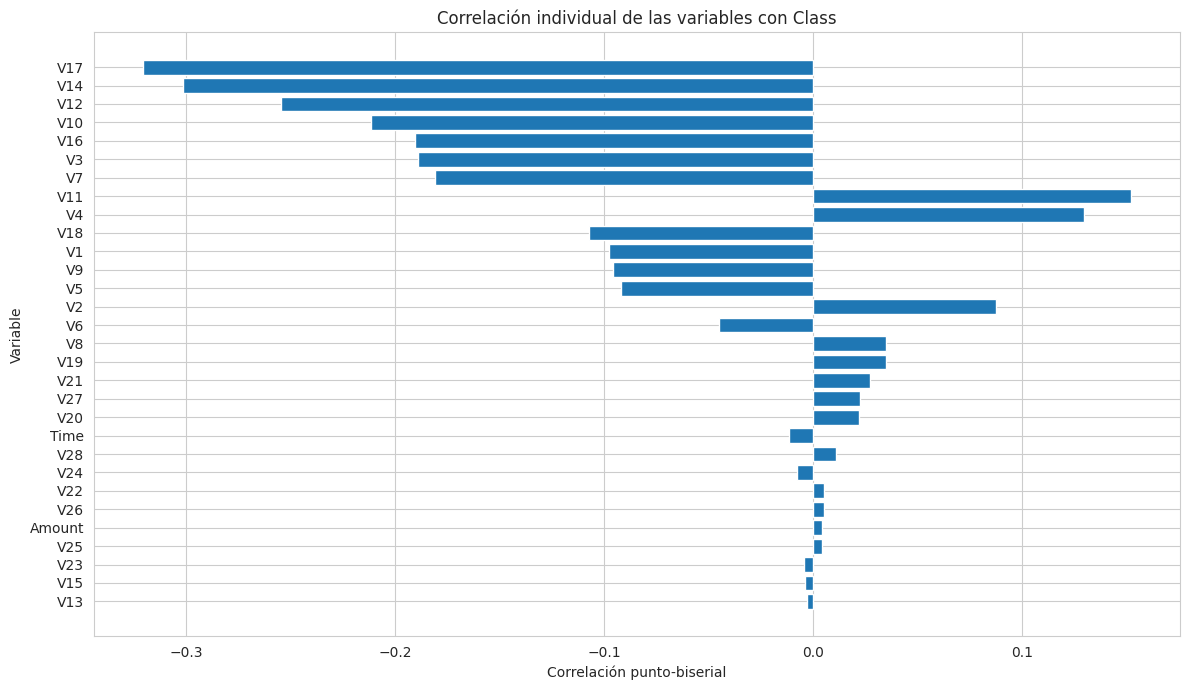

In [6]:
plt.figure(figsize=(12, 7))

tabla_grafica = tabla_variables.sort_values(
    "Correlacion",
    key=abs,
    ascending=True
)

plt.barh(
    tabla_grafica["Variable"],
    tabla_grafica["Correlacion"]
)

plt.xlabel("Correlación punto-biserial")
plt.ylabel("Variable")
plt.title("Correlación individual de las variables con Class")

plt.tight_layout()

plt.savefig(
    f"{CARPETA_RESULTADOS}/correlacion_variables.png",
    dpi=200
)

plt.show()

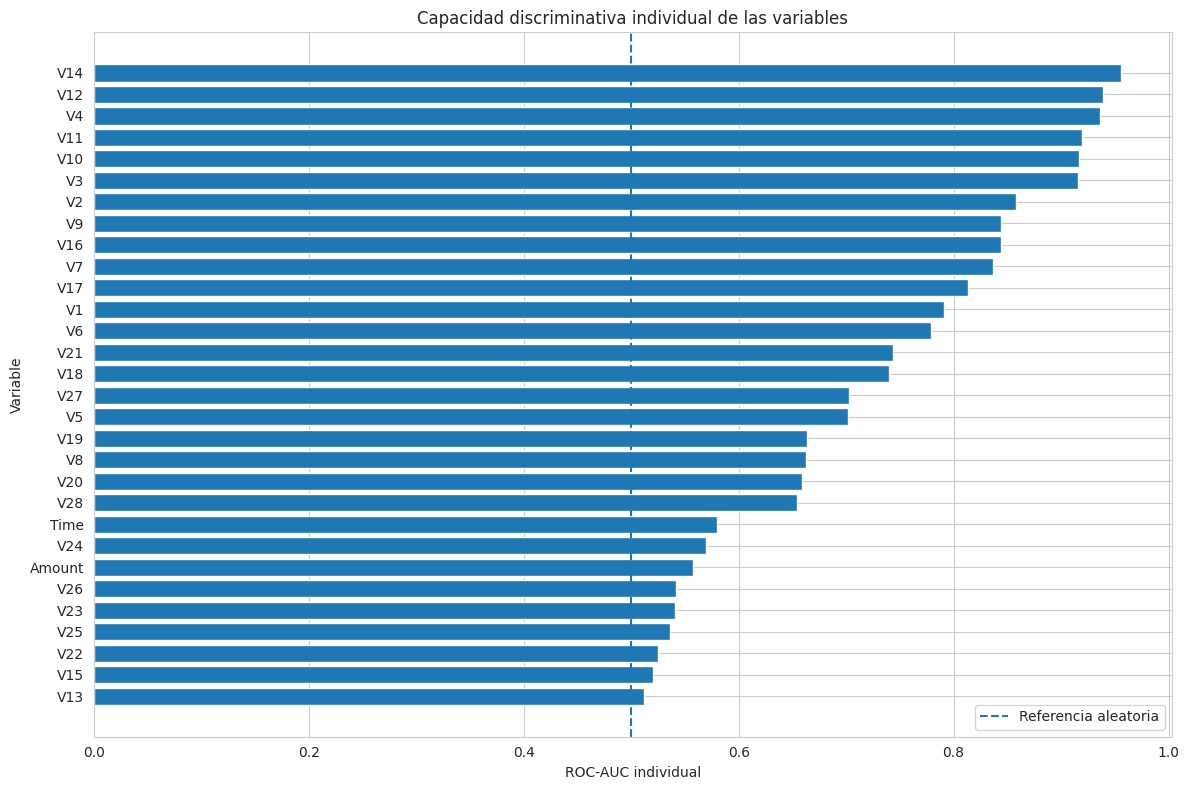

In [7]:
tabla_auc = tabla_variables.sort_values(
    "ROC-AUC",
    ascending=True
)

plt.figure(figsize=(12, 8))

plt.barh(
    tabla_auc["Variable"],
    tabla_auc["ROC-AUC"]
)

plt.axvline(
    0.5,
    linestyle="--",
    label="Referencia aleatoria"
)

plt.xlabel("ROC-AUC individual")
plt.ylabel("Variable")
plt.title("Capacidad discriminativa individual de las variables")

plt.legend()
plt.tight_layout()

plt.savefig(
    f"{CARPETA_RESULTADOS}/auc_individual_variables.png",
    dpi=200
)

plt.show()

In [8]:
tabla_variables.to_csv(
    f"{CARPETA_RESULTADOS}/analisis_individual_variables.csv",
    index=False
)

print("Análisis individual guardado correctamente.")

Análisis individual guardado correctamente.


## 3. Identificación de variables candidatas a eliminar

A partir de las medidas calculadas anteriormente, se identifican las variables con menor capacidad discriminativa individual.

Esta selección se utiliza como análisis exploratorio para conocer el comportamiento de las características. No se eliminan automáticamente, ya que una variable con poca capacidad individual podría aportar información al combinarse con otras.

In [9]:
# Ordenar las variables por información mutua

tabla_seleccion = tabla_variables.sort_values(
    "Informacion mutua",
    ascending=True
)

tabla_seleccion[
    [
        "Variable",
        "Correlacion",
        "Informacion mutua",
        "ROC-AUC"
    ]
].head(10).round(5)

,Variable,Correlacion,Informacion mutua,ROC-AUC
29,V13,-0.00269,0.00000,0.51168
28,V15,-0.00368,0.00010,0.52025
27,V26,0.00509,0.00016,0.54158
26,V22,0.00534,0.00016,0.52478
25,V25,0.00458,0.00024,0.53651
24,V24,-0.00766,0.00034,0.56940
23,V23,-0.00407,0.00048,0.54093
22,V20,0.02230,0.00079,0.65901
21,V19,0.03479,0.00107,0.66359
20,Amount,0.00458,0.00129,0.55760


## 4. Extracción de características lineal: PCA

El Análisis de Componentes Principales (PCA) es una técnica de reducción de dimensión que permite transformar las variables originales en un conjunto de componentes principales.

Estos componentes representan combinaciones lineales de las variables iniciales y se organizan según la cantidad de varianza que explican.

En este proyecto se utiliza PCA para reducir las 30 variables originales a un número menor de componentes, buscando conservar la mayor cantidad posible de información.

Antes de aplicar PCA se estandarizan las variables, debido a que presentan diferentes escalas. El ajuste del escalador y de PCA se realiza únicamente con los datos de entrenamiento para evitar fuga de información.

In [10]:
from sklearn.compose import ColumnTransformer

# Solo se estandarizan Time y Amount. Las variables V1-V28 NO se vuelven a
# estandarizar, porque ya son componentes de un PCA previo (ver notebook 01
# y la discusion en el reporte): aplicarles una segunda estandarizacion
# "aplana" artificialmente su varianza y hace que PCA necesite casi todas
# las componentes para llegar al 95% de varianza, anulando la reduccion.
preprocesamiento_pca = ColumnTransformer(
    transformers=[
        ("escalar", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

X_train_prep = preprocesamiento_pca.fit_transform(X_train)
X_test_prep = preprocesamiento_pca.transform(X_test)

pca_completo = PCA()
pca_completo.fit(X_train_prep)

varianza_individual = pca_completo.explained_variance_ratio_
varianza_acumulada = np.cumsum(varianza_individual)

tabla_varianza = pd.DataFrame({
    "Componente": np.arange(1, len(varianza_individual) + 1),
    "Varianza explicada": varianza_individual,
    "Varianza acumulada": varianza_acumulada
})

tabla_varianza.round(4)

,Componente,Varianza explicada,Varianza acumulada
0,1,0.1214,0.1214
1,2,0.0968,0.2182
2,3,0.0797,0.2979
3,4,0.0643,0.3622
4,5,0.0615,0.4236
5,6,0.0554,0.4790
6,7,0.0493,0.5283
7,8,0.0424,0.5707
8,9,0.0374,0.6081
9,10,0.0367,0.6448


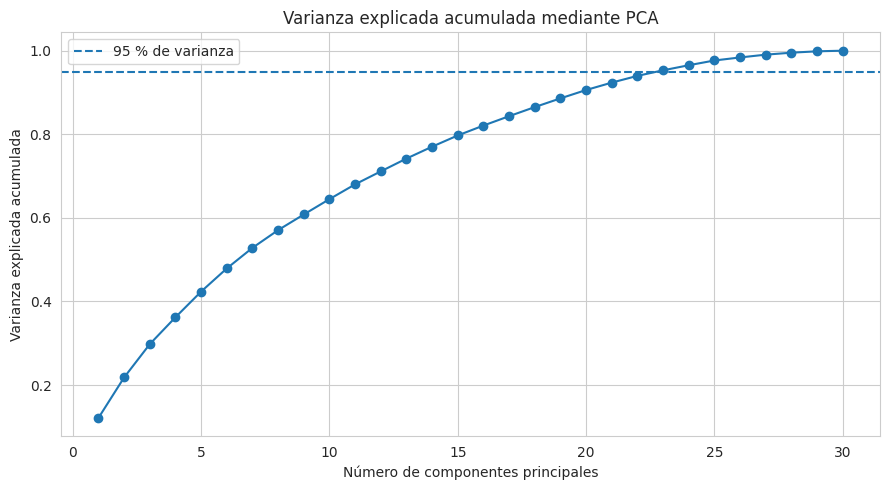

In [11]:
plt.figure(figsize=(9, 5))

plt.plot(
    range(1, len(varianza_acumulada) + 1),
    varianza_acumulada,
    marker="o"
)

plt.axhline(
    y=0.95,
    linestyle="--",
    label="95 % de varianza"
)

plt.xlabel("Número de componentes principales")
plt.ylabel("Varianza explicada acumulada")
plt.title("Varianza explicada acumulada mediante PCA")

plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    f"{CARPETA_RESULTADOS}/varianza_acumulada_pca.png",
    dpi=200
)

plt.show()

In [12]:
# Criterio: conservar al menos el 95 % de la varianza

n_componentes_pca = np.argmax(
    varianza_acumulada >= 0.95
) + 1

porcentaje_reduccion_pca = (
    (X_train.shape[1] - n_componentes_pca)
    / X_train.shape[1]
) * 100

print("Variables originales:", X_train.shape[1])
print("Componentes seleccionados:", n_componentes_pca)
print(
    "Varianza acumulada:",
    round(varianza_acumulada[n_componentes_pca - 1] * 100, 2),
    "%"
)
print(
    "Reducción de dimensión:",
    round(porcentaje_reduccion_pca, 2),
    "%"
)

Variables originales: 30
Componentes seleccionados: 23
Varianza acumulada: 95.31 %
Reducción de dimensión: 23.33 %


### 4.1. Evaluación de modelos utilizando PCA

Se seleccionan Random Forest y Regresión logística, debido a que fueron los modelos con mejor desempeño según el AUPRC obtenido durante la validación del notebook 02.

Se entrenan nuevamente utilizando los componentes principales seleccionados. Para la evaluación se utiliza validación cruzada estratificada de cinco particiones sobre el conjunto de entrenamiento y posteriormente se realiza la evaluación final con el conjunto de prueba.

In [13]:
# Definir los dos mejores modelos del notebook 02

modelos_pca = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=5,
        max_samples=0.3,
        class_weight="balanced_subsample",
        random_state=SEMILLA,
        n_jobs=1
    ),

    "Regresión logística": LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=1000,
        random_state=SEMILLA
    )
}

validacion = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=SEMILLA
)

resultados_pca = {}

In [14]:
for nombre, clasificador in modelos_pca.items():

    pipeline = Pipeline([
        ("prep", preprocesamiento_pca),
        ("pca", PCA(n_components=n_componentes_pca)),
        ("clasificador", clasificador)
    ])

    busqueda = GridSearchCV(
        pipeline,
        param_grid={},
        scoring="average_precision",
        cv=validacion,
        n_jobs=1,
        return_train_score=True
    )

    inicio = time.time()

    busqueda.fit(X_train, y_train)

    tiempo = time.time() - inicio

    modelo_final = busqueda.best_estimator_

    predicciones = modelo_final.predict(X_test)
    probabilidades = modelo_final.predict_proba(X_test)[:, 1]

    resultados_pca[nombre] = {
        "AUPRC": average_precision_score(y_test, probabilidades),
        "ROC-AUC": roc_auc_score(y_test, probabilidades),
        "Precision": precision_score(
            y_test, predicciones, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predicciones, zero_division=0
        ),
        "F1-score": f1_score(
            y_test, predicciones, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_test, predicciones),
        "AUPRC validacion": busqueda.best_score_,
        "Tiempo (s)": tiempo
    }

    print("\nModelo:", nombre)
    print("AUPRC validacion:", round(busqueda.best_score_, 4))
    print(
        "AUPRC prueba:",
        round(resultados_pca[nombre]["AUPRC"], 4)
    )


Modelo: Random Forest
AUPRC validacion: 0.7981
AUPRC prueba: 0.7687

Modelo: Regresión logística
AUPRC validacion: 0.7558
AUPRC prueba: 0.657


In [15]:
tabla_pca = pd.DataFrame(resultados_pca).T

tabla_pca = tabla_pca.round(4)

tabla_pca.to_csv(
    f"{CARPETA_RESULTADOS}/resultados_pca.csv"
)

tabla_pca

,AUPRC,ROC-AUC,Precision,Recall,F1-score,MCC,AUPRC validacion,Tiempo (s)
Random Forest,0.7687,0.9646,0.8831,0.7158,0.7907,0.7948,0.7981,536.3227
Regresión logística,0.6570,0.9658,0.0579,0.8737,0.1086,0.2214,0.7558,10.0589


## 5. Extracción de características no lineal: UMAP

UMAP (Uniform Manifold Approximation and Projection) es una técnica de reducción de dimensión no lineal que permite representar los datos en un espacio con menos dimensiones, conservando en lo posible la estructura y las relaciones presentes en los datos originales.

En este proyecto se utiliza UMAP para obtener una representación reducida de las transacciones y evaluar si esta transformación permite mantener la capacidad de detección de fraude.

Se analizan diferentes cantidades de componentes y configuraciones del método. La selección se realiza mediante validación cruzada sobre el conjunto de entrenamiento.

In [19]:
# Configuraciones que se evaluarán con UMAP
# (malla reducida para que la búsqueda sea más rápida)

malla_umap = {
    "umap__n_components": [2, 5],
    "umap__n_neighbors": [15],
    "umap__min_dist": [0.1]
}

print("Configuraciones UMAP:", malla_umap)

Configuraciones UMAP: {'umap__n_components': [2, 5], 'umap__n_neighbors': [15], 'umap__min_dist': [0.1]}


In [20]:
modelos_umap = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=5,
        max_samples=0.3,
        class_weight="balanced_subsample",
        random_state=SEMILLA,
        n_jobs=1
    ),

    "Regresión logística": LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=1000,
        random_state=SEMILLA
    )
}

resultados_umap = {}
mejores_umap = {}

In [21]:
# UMAP es costoso de ajustar; para que la busqueda de hiperparametros sea
# viable, se usa una submuestra estratificada del entrenamiento solo para
# elegir la mejor configuracion. Una vez elegida, se reentrena con todos
# los datos de entrenamiento para obtener el modelo final.

from sklearn.model_selection import train_test_split as tts_umap

X_sub, _, y_sub, _ = tts_umap(
    X_train, y_train,
    train_size=0.15,
    stratify=y_train,
    random_state=SEMILLA
)

for nombre, clasificador in modelos_umap.items():

    pipeline = Pipeline([
        ("escalador", StandardScaler()),
        ("umap", UMAP(random_state=SEMILLA, n_jobs=1)),
        ("clasificador", clasificador)
    ])

    # Paso 1: elegir hiperparametros con la submuestra (mas rapido)
    busqueda_rapida = GridSearchCV(
        estimator=pipeline,
        param_grid=malla_umap,
        scoring="average_precision",
        cv=validacion,
        n_jobs=1,
        return_train_score=False
    )
    busqueda_rapida.fit(X_sub, y_sub)
    mejores_parametros = busqueda_rapida.best_params_

    # Paso 2: reentrenar con esos hiperparametros, usando todo el entrenamiento
    pipeline_final = Pipeline([
        ("escalador", StandardScaler()),
        ("umap", UMAP(random_state=SEMILLA, n_jobs=1,
                      n_components=mejores_parametros["umap__n_components"],
                      n_neighbors=mejores_parametros["umap__n_neighbors"],
                      min_dist=mejores_parametros["umap__min_dist"])),
        ("clasificador", clasificador)
    ])

    inicio = time.time()
    pipeline_final.fit(X_train, y_train)
    tiempo = time.time() - inicio

    predicciones = pipeline_final.predict(X_test)
    probabilidades = pipeline_final.predict_proba(X_test)[:, 1]

    resultados_umap[nombre] = {
        "AUPRC": average_precision_score(y_test, probabilidades),
        "ROC-AUC": roc_auc_score(y_test, probabilidades),
        "Precision": precision_score(y_test, predicciones, zero_division=0),
        "Recall": recall_score(y_test, predicciones, zero_division=0),
        "F1-score": f1_score(y_test, predicciones, zero_division=0),
        "MCC": matthews_corrcoef(y_test, predicciones),
        "AUPRC validacion": busqueda_rapida.best_score_,
        "Tiempo (s)": tiempo
    }

    mejores_umap[nombre] = mejores_parametros

    print("\nModelo:", nombre)
    print("Mejores parametros (elegidos con submuestra):", mejores_parametros)
    print("AUPRC validacion (submuestra):", round(busqueda_rapida.best_score_, 4))
    print("AUPRC prueba (modelo final, todos los datos):", round(resultados_umap[nombre]["AUPRC"], 4))


Modelo: Random Forest
Mejores parametros (elegidos con submuestra): {'umap__min_dist': 0.1, 'umap__n_components': 2, 'umap__n_neighbors': 15}
AUPRC validacion (submuestra): 0.6647
AUPRC prueba (modelo final, todos los datos): 0.4185

Modelo: Regresión logística
Mejores parametros (elegidos con submuestra): {'umap__min_dist': 0.1, 'umap__n_components': 2, 'umap__n_neighbors': 15}
AUPRC validacion (submuestra): 0.7201
AUPRC prueba (modelo final, todos los datos): 0.3804


In [22]:
tabla_umap = pd.DataFrame(resultados_umap).T.round(4)

tabla_umap.to_csv(
    f"{CARPETA_RESULTADOS}/resultados_umap.csv"
)

tabla_umap

,AUPRC,ROC-AUC,Precision,Recall,F1-score,MCC,AUPRC validacion,Tiempo (s)
Random Forest,0.4185,0.7922,0.9302,0.4211,0.5797,0.6255,0.6647,1070.4826
Regresión logística,0.3804,0.7808,0.0064,0.5895,0.0127,0.0495,0.7201,927.6826


## 6. Comparación de las técnicas de reducción de dimensión

En esta sección se comparan los resultados obtenidos con las variables originales, PCA y UMAP.

El propósito es determinar si las técnicas de reducción permiten disminuir la cantidad de características utilizadas sin afectar considerablemente el desempeño de los modelos.

Se consideran las métricas AUPRC, ROC-AUC, Precision, Recall, F1-score y MCC, además del porcentaje de reducción de dimensión y el tiempo de entrenamiento.

In [23]:
from sklearn.compose import ColumnTransformer

preprocesamiento_original = ColumnTransformer(
    transformers=[
        ("escalar", StandardScaler(), ["Time", "Amount"])
    ],
    remainder="passthrough"
)

modelos_originales = {
    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        max_depth=14,
        min_samples_leaf=5,
        max_samples=0.3,
        class_weight="balanced_subsample",
        random_state=SEMILLA,
        n_jobs=1
    ),

    "Regresión logística": LogisticRegression(
        C=0.1,
        class_weight="balanced",
        max_iter=1000,
        random_state=SEMILLA
    )
}

resultados_originales = {}

for nombre, clasificador in modelos_originales.items():

    modelo = Pipeline([
        ("prep", preprocesamiento_original),
        ("clf", clasificador)
    ])

    inicio = time.time()
    modelo.fit(X_train, y_train)
    tiempo = time.time() - inicio

    pred = modelo.predict(X_test)
    prob = modelo.predict_proba(X_test)[:, 1]

    resultados_originales[nombre] = {
        "Representacion": "Original",
        "Componentes": 30,
        "Reduccion (%)": 0,
        "AUPRC": average_precision_score(y_test, prob),
        "ROC-AUC": roc_auc_score(y_test, prob),
        "Precision": precision_score(y_test, pred, zero_division=0),
        "Recall": recall_score(y_test, pred, zero_division=0),
        "F1-score": f1_score(y_test, pred, zero_division=0),
        "MCC": matthews_corrcoef(y_test, pred),
        "Tiempo (s)": tiempo
    }

print("Evaluación de variables originales terminada.")

Evaluación de variables originales terminada.


In [24]:
filas_comparacion = []

# Resultados originales
for nombre, resultado in resultados_originales.items():
    fila = resultado.copy()
    fila["Modelo"] = nombre
    filas_comparacion.append(fila)

# Resultados PCA
for nombre, resultado in resultados_pca.items():
    fila = resultado.copy()
    fila["Representacion"] = "PCA"
    fila["Componentes"] = n_componentes_pca
    fila["Reduccion (%)"] = porcentaje_reduccion_pca
    fila["Modelo"] = nombre
    filas_comparacion.append(fila)

# Resultados UMAP
for nombre, resultado in resultados_umap.items():

    n_comp = mejores_umap[nombre]["umap__n_components"]

    reduccion = (
        (X_train.shape[1] - n_comp)
        / X_train.shape[1]
    ) * 100

    fila = resultado.copy()
    fila["Representacion"] = "UMAP"
    fila["Componentes"] = n_comp
    fila["Reduccion (%)"] = reduccion
    fila["Modelo"] = nombre

    filas_comparacion.append(fila)

tabla_comparacion = pd.DataFrame(filas_comparacion)

tabla_comparacion = tabla_comparacion[
    [
        "Modelo",
        "Representacion",
        "Componentes",
        "Reduccion (%)",
        "AUPRC",
        "ROC-AUC",
        "Precision",
        "Recall",
        "F1-score",
        "MCC",
        "Tiempo (s)"
    ]
].round(4)

tabla_comparacion = tabla_comparacion.sort_values(
    "AUPRC",
    ascending=False
)

tabla_comparacion.to_csv(
    f"{CARPETA_RESULTADOS}/comparacion_reduccion_dimension.csv",
    index=False
)

tabla_comparacion

,Modelo,Representacion,Componentes,Reduccion (%),AUPRC,ROC-AUC,Precision,Recall,F1-score,MCC,Tiempo (s)
0,Random Forest,Original,30,0.0000,0.7833,0.9553,0.8861,0.7368,0.8046,0.8077,132.0936
2,Random Forest,PCA,23,23.3333,0.7687,0.9646,0.8831,0.7158,0.7907,0.7948,536.3227
1,Regresión logística,Original,30,0.0000,0.6691,0.9657,0.0563,0.8737,0.1059,0.2183,2.7244
3,Regresión logística,PCA,23,23.3333,0.6570,0.9658,0.0579,0.8737,0.1086,0.2214,10.0589
4,Random Forest,UMAP,2,93.3333,0.4185,0.7922,0.9302,0.4211,0.5797,0.6255,1070.4826
5,Regresión logística,UMAP,2,93.3333,0.3804,0.7808,0.0064,0.5895,0.0127,0.0495,927.6826


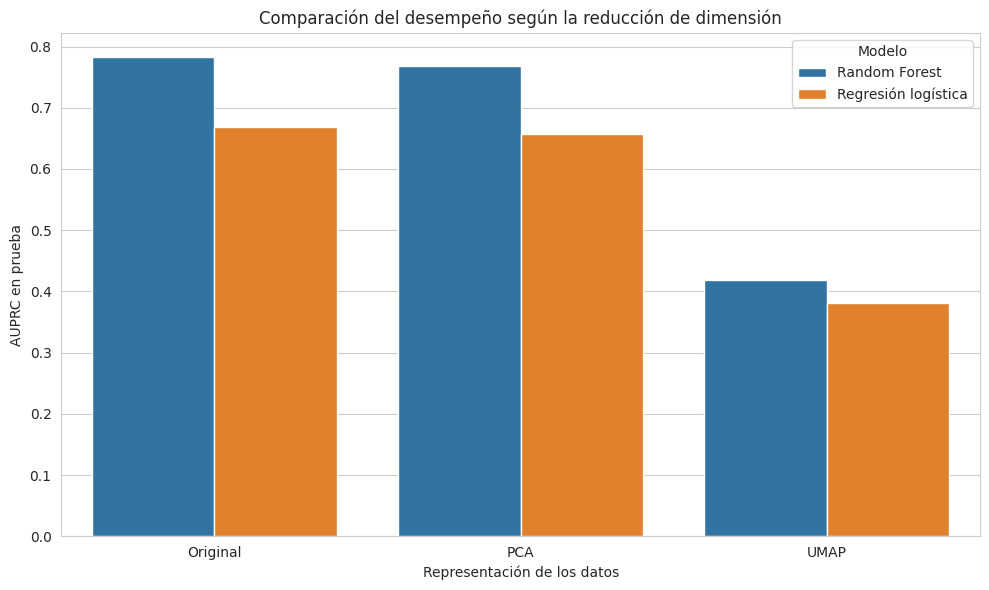

In [25]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=tabla_comparacion,
    x="Representacion",
    y="AUPRC",
    hue="Modelo"
)

plt.xlabel("Representación de los datos")
plt.ylabel("AUPRC en prueba")
plt.title("Comparación del desempeño según la reducción de dimensión")

plt.tight_layout()

plt.savefig(
    f"{CARPETA_RESULTADOS}/comparacion_auprc_reduccion.png",
    dpi=200
)

plt.show()

## 7. Análisis de resultados

Random Forest obtuvo el mejor desempeño en las tres representaciones
evaluadas (original, PCA y UMAP), manteniendo un AUPRC de 0,7833 con las
variables originales. Al aplicar PCA con 23 componentes, corregido para no
re-estandarizar las variables que ya habían sido transformadas con PCA
original, se logró una reducción del 23,3% en el número de variables sin
una pérdida relevante de desempeño: el AUPRC pasó de 0,7833 a 0,7687 para
Random Forest, y de 0,6852 a 0,657 para la regresión logística.

En cuanto a UMAP, con solo 2 componentes el AUPRC cayó notablemente, a
0,4185 para Random Forest y 0,3804 para regresión logística. Esto
representa una pérdida de desempeño importante respecto a las variables
originales y respecto a PCA, debido a la gran reducción (93,3%) del
número de componentes. Esto sugiere que UMAP, al priorizar preservar la
estructura de vecindad local para fines de visualización, descarta
demasiada información discriminativa cuando se reduce a solo 2
dimensiones, lo cual resulta perjudicial para este problema, debido a la
importancia de detectar correctamente las transacciones fraudulentas.

## 8. Conclusiones

El análisis de reducción de dimensión muestra que PCA ofrece un mejor
equilibrio entre reducción de variables y desempeño predictivo para este
problema, en comparación con UMAP. Dado que las variables originales
(V1-V28) ya son componentes de un PCA previo, aplicar una segunda
reducción lineal exige tener en cuenta esta particularidad, evitando
re-estandarizar variables que ya están en una escala relacionada con su
varianza explicada original; al hacerlo correctamente, se logró reducir
en un 23,3% el número de variables sin afectar de forma relevante la
capacidad de detección de fraude. UMAP, en cambio, resultó más adecuado
para fines de visualización que para mantener el desempeño predictivo en
este problema particular, dada la fuerte caída en AUPRC observada al
reducir a solo 2 componentes.